On Kaggle, turn on **GPU** in Notebook Settings. `DataParallel` is used only if more than one GPU is available; many Kaggle sessions expose just one GPU.

In [14]:
import os, json, math, random, time
from pathlib import Path
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)
from tqdm.auto import tqdm
from transformers import VideoMAEModel, get_cosine_schedule_with_warmup

# ---------------- paths ----------------
SEED       = 42
DATA_DIR   = Path("/kaggle/input/datasets/janaahmedmostafa/shop-dataset")
WORK_DIR   = Path("/kaggle/working")
CSV_PATH   = DATA_DIR / "video_metadata (1).csv"      # the file your notebook actually loaded

CHECKPOINT_DIR = WORK_DIR / "checkpoints_videomae"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
LAST_CKPT  = CHECKPOINT_DIR / "last.pt"               # full state, saved every epoch (for resume)
BEST_CKPT  = CHECKPOINT_DIR / "best.pt"               # best val-F1 (model weights + meta only)
STATS_PATH = WORK_DIR / "mean_std.json"               # cached dataset mean/std

# ---------------- model / training settings ----------------
MODEL_NAME     = "MCG-NJU/videomae-base"
NUM_FRAMES     = 16        # videomae-base was pretrained with 16 frames
IMAGE_SIZE     = 224       # ... and 224x224 (do not change unless you change the model config)
BATCH_SIZE     = 4
ACCUM_STEPS    = 2         # effective batch = BATCH_SIZE * ACCUM_STEPS
EPOCHS         = 10
PATIENCE       = 3         # early stopping on val F1
NUM_WORKERS    = 2
TEMPORAL_TYPE  = "lstm"    # "lstm" or "transformer"
GRAD_CHECKPOINTING = True  # saves a lot of GPU memory, a bit slower
RESUME         = True      # continue from last.pt if it exists

# ---------------- normalization ----------------
USE_DATASET_STATS = True   # True: use MEAN/STD computed from your train set; False: ImageNet stats
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

RUN_DUPLICATE_AUDIT = False  # optional ResNet18 near-duplicate check (also builds leakage-safe groups)
SIMILARITY_THRESHOLD = 0.98

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
device  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"
print("Device:", device, "| GPUs:", torch.cuda.device_count())

Device: cuda | GPUs: 2


In [1]:
import os
import random
import hashlib
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import functional as TF

from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
from sklearn.metrics.pairwise import cosine_similarity
from tqdm.auto import tqdm


import os
import zipfile

!pip install -q gdown
import gdown


file_id = '1KCKfyIGbQi8a7bIYta3LM8dFStxVzVX-'
zip_path = 'Shop_DataSet.zip'
extract_path = './dataset'

# 3. Download the file from Google Drive
url = f'https://drive.google.com/uc?id={file_id}'
gdown.download(url, zip_path, quiet=False)

# 4. Extract the zip file
os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Unzipping complete!")
SEED = 42
DATA_DIR = Path("/kaggle/working/dataset/Shop DataSet")
WORK_DIR = Path("/kaggle/working")
CSV_PATH = "/kaggle/input/datasets/janaahmedmostafa/meta-data"



def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Available GPUs:", torch.cuda.device_count())
print("Dataset directory exists:", DATA_DIR.exists())

Downloading...
From (original): https://drive.google.com/uc?id=1KCKfyIGbQi8a7bIYta3LM8dFStxVzVX-
From (redirected): https://drive.google.com/uc?id=1KCKfyIGbQi8a7bIYta3LM8dFStxVzVX-&confirm=t&uuid=c08fbac0-5236-455c-88cc-6eaa56467f18
To: /kaggle/working/Shop_DataSet.zip
100%|██████████| 1.78G/1.78G [00:16<00:00, 111MB/s] 


Unzipping complete!
Device: cuda
Available GPUs: 2
Dataset directory exists: True


In [2]:
VIDEO_EXTENSIONS = {".mp4", ".avi", ".mov", ".mkv"}

def inspect_video(video_path):
    cap = cv2.VideoCapture(str(video_path))
    try:
        if not cap.isOpened():
            return None
        fps = float(cap.get(cv2.CAP_PROP_FPS))
        frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
        height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
        duration = frame_count / fps if fps > 0 else np.nan
        return {
            "video": video_path.name,
            "class": video_path.parent.name.strip().lower(),
            "frame_count": frame_count,
            "fps": fps,
            "duration_seconds": duration,
            "width": width,
            "height": height,
            "path": str(video_path.resolve()),
        }
    finally:
        cap.release()

def build_metadata(dataset_dir):
    records = []
    for video_path in sorted(Path(dataset_dir).rglob("*")):
        if video_path.suffix.lower() not in VIDEO_EXTENSIONS:
            continue
        info = inspect_video(video_path)
        if info is not None and info["frame_count"] > 0:
            records.append(info)

    metadata = pd.DataFrame(records)
    if metadata.empty:
        raise RuntimeError(
            f"No readable videos found under {dataset_dir}. "
            "Check DATA_DIR and the extracted folder structure."
        )
    return metadata

df = build_metadata(DATA_DIR)
print("Videos found:", len(df))
print("\nClass counts:")
print(df["class"].value_counts())
display(df.head())


Videos found: 855

Class counts:
class
non shop lifters    531
shop lifters        324
Name: count, dtype: int64


,video,class,frame_count,fps,duration_seconds,width,height,path
0,shop_lifter_n_0.mp4,non shop lifters,450,25.0,18.0,704,576,/kaggle/working/dataset/Shop DataSet/non shop ...
1,shop_lifter_n_0_1.mp4,non shop lifters,450,25.0,18.0,704,576,/kaggle/working/dataset/Shop DataSet/non shop ...
2,shop_lifter_n_1.mp4,non shop lifters,450,25.0,18.0,704,576,/kaggle/working/dataset/Shop DataSet/non shop ...
3,shop_lifter_n_10.mp4,non shop lifters,475,25.0,19.0,704,576,/kaggle/working/dataset/Shop DataSet/non shop ...
4,shop_lifter_n_100.mp4,non shop lifters,400,25.0,16.0,704,576,/kaggle/working/dataset/Shop DataSet/non shop ...


SHA-256 hashes identify files with exactly the same bytes, even when filenames differ. If identical files have conflicting labels, those rows are excluded from the clean set 

In [3]:
def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

df["file_hash"] = [
    file_sha256(path) for path in tqdm(df["path"], desc="Hashing videos")
]

label_counts = df.groupby("file_hash")["class"].nunique()
conflict_hashes = set(label_counts[label_counts > 1].index)

conflicts = df[df["file_hash"].isin(conflict_hashes)].copy()
conflicts.to_csv(WORK_DIR / "duplicate_label_conflicts.csv", index=False)

before = len(df)
# Do not silently choose a label when identical bytes have conflicting labels.
df_clean = df[~df["file_hash"].isin(conflict_hashes)].copy()
df_clean = df_clean.drop_duplicates(subset="file_hash", keep="first")
df_clean = df_clean.reset_index(drop=True)

print("Rows before cleaning:", before)
print("Exact duplicate copies removed:", before - len(df_clean) - len(conflicts))
print("Rows with conflicting labels to review:", len(conflicts))
print("Rows remaining:", len(df_clean))
print("Conflict report:", WORK_DIR / "duplicate_label_conflicts.csv")

df_clean.to_csv(WORK_DIR / "videos_dataset_clean.csv", index=False)

Hashing videos:   0%|          | 0/855 [00:00<?, ?it/s]

Rows before cleaning: 855
Exact duplicate copies removed: 218
Rows with conflicting labels to review: 0
Rows remaining: 637
Conflict report: /kaggle/working/duplicate_label_conflicts.csv


## video embeddings

This optional audit uses a pretrained ResNet18 . The final 3D CNN classifier below is still initialized and trained from scratch.

 threshold such as `0.98`, inspect the pairs, and tune it for your footage. Similar background/camera views can produce high similarity even when actions differ.

In [4]:
from torchvision import models

EMBEDDING_FRAMES = 8
SIMILARITY_THRESHOLD = 0.98

def make_embedding_encoder(device):
    weights = models.ResNet18_Weights.DEFAULT
    model = models.resnet18(weights=weights)
    model.fc = nn.Identity()
    model.eval().to(device)
    return model, weights.transforms()

def video_embedding(video_path, encoder, preprocess, device, num_frames=8):
    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        cap.release()
        raise ValueError(f"Cannot open video: {video_path}")

    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total <= 0:
        cap.release()
        raise ValueError(f"No frames: {video_path}")

    indices = np.linspace(0, total - 1, min(num_frames, total), dtype=int)
    frame_features = []

    with torch.inference_mode():
        for index in indices:
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(index))
            ok, frame = cap.read()
            if not ok:
                continue
            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            image = transforms.ToPILImage()(frame)
            tensor = preprocess(image).unsqueeze(0).to(device)
            feature = encoder(tensor).flatten(1)
            frame_features.append(feature.squeeze(0).cpu().numpy().astype(np.float32))

    cap.release()
    if not frame_features:
        raise ValueError(f"Could not read sampled frames: {video_path}")

    # Use float32; no need for float64 for these embeddings.
    return np.mean(np.stack(frame_features), axis=0, dtype=np.float32)

try:
    audit_encoder, audit_preprocess = make_embedding_encoder(device)
    embedding_rows = []
    valid_indices = []

    for idx, row in tqdm(df_clean.iterrows(), total=len(df_clean), desc="Video embeddings"):
        try:
            embedding_rows.append(
                video_embedding(row["path"], audit_encoder, audit_preprocess, device,
                                num_frames=EMBEDDING_FRAMES)
            )
            valid_indices.append(idx)
        except (ValueError, cv2.error) as exc:
            print("Skipped:", row["path"], "|", exc)

    audit_df = df_clean.loc[valid_indices].reset_index(drop=True)
    X = np.asarray(embedding_rows, dtype=np.float32)

    # Normalize embeddings, then dot product = cosine similarity.
    X /= np.maximum(np.linalg.norm(X, axis=1, keepdims=True), 1e-12).astype(np.float32)
    similarity_matrix = X @ X.T

    left, right = np.where(np.triu(similarity_matrix, k=1) >= SIMILARITY_THRESHOLD)
    near_duplicates = pd.DataFrame({
        "path_1": audit_df.iloc[left]["path"].to_numpy(),
        "class_1": audit_df.iloc[left]["class"].to_numpy(),
        "path_2": audit_df.iloc[right]["path"].to_numpy(),
        "class_2": audit_df.iloc[right]["class"].to_numpy(),
        "cosine_similarity": similarity_matrix[left, right].astype(np.float32),
    }).sort_values("cosine_similarity", ascending=False)

    near_duplicates.to_csv(WORK_DIR / "near_duplicate_video_pairs.csv", index=False)
    print("Embedding matrix dtype:", X.dtype)
    print("Embedding matrix shape:", X.shape)
    print("Potential near-duplicate pairs:", len(near_duplicates))
    display(near_duplicates.head(25))
    print("Pair report:", WORK_DIR / "near_duplicate_video_pairs.csv")

except Exception as exc:
    print("Embedding audit did not run:", repr(exc))
    print("Check Kaggle Internet/weights or skip this optional audit.")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 228MB/s]


Video embeddings:   0%|          | 0/637 [00:00<?, ?it/s]

Embedding matrix dtype: float32
Embedding matrix shape: (637, 512)
Potential near-duplicate pairs: 107115


,path_1,class_1,path_2,class_2,cosine_similarity
76351,/kaggle/working/dataset/Shop DataSet/shop lift...,shop lifters,/kaggle/working/dataset/Shop DataSet/shop lift...,shop lifters,0.999592
58137,/kaggle/working/dataset/Shop DataSet/non shop ...,non shop lifters,/kaggle/working/dataset/Shop DataSet/non shop ...,non shop lifters,0.999547
98356,/kaggle/working/dataset/Shop DataSet/shop lift...,shop lifters,/kaggle/working/dataset/Shop DataSet/shop lift...,shop lifters,0.999530
71440,/kaggle/working/dataset/Shop DataSet/non shop ...,non shop lifters,/kaggle/working/dataset/Shop DataSet/non shop ...,non shop lifters,0.999471
75952,/kaggle/working/dataset/Shop DataSet/shop lift...,shop lifters,/kaggle/working/dataset/Shop DataSet/shop lift...,shop lifters,0.999468
76477,/kaggle/working/dataset/Shop DataSet/shop lift...,shop lifters,/kaggle/working/dataset/Shop DataSet/shop lift...,shop lifters,0.999468
24778,/kaggle/working/dataset/Shop DataSet/non shop ...,non shop lifters,/kaggle/working/dataset/Shop DataSet/non shop ...,non shop lifters,0.999457
101581,/kaggle/working/dataset/Shop DataSet/shop lift...,shop lifters,/kaggle/working/dataset/Shop DataSet/shop lift...,shop lifters,0.999438
98355,/kaggle/working/dataset/Shop DataSet/shop lift...,shop lifters,/kaggle/working/dataset/Shop DataSet/shop lift...,shop lifters,0.999436
49354,/kaggle/working/dataset/Shop DataSet/non shop ...,non shop lifters,/kaggle/working/dataset/Shop DataSet/non shop ...,non shop lifters,0.999436


Pair report: /kaggle/working/near_duplicate_video_pairs.csv


### Review the near-duplicate report before splitting

Open `/kaggle/working/near_duplicate_video_pairs.csv`. If two clips come from the same original CCTV recording or overlap in time, give them the same `source_group` in the next cell. Do not group videos just because their backgrounds look alike.

If you already have a recording/source ID, use it directly. If every video is an independent recording, leave each video in its own group.

In [5]:
df_clean["source_group"] = df_clean["path"]

GROUP_CSV = WORK_DIR / "video_source_groups.csv"
if GROUP_CSV.exists():
    group_map = pd.read_csv(GROUP_CSV)
    if {"path", "source_group"}.issubset(group_map.columns):
        df_clean = df_clean.drop(columns=["source_group"]).merge(
            group_map[["path", "source_group"]], on="path", how="left"
        )
        df_clean["source_group"] = df_clean["source_group"].fillna(df_clean["path"])

print("Videos:", len(df_clean))
print("Distinct source groups:", df_clean["source_group"].nunique())
print("Groups with multiple clips:", int((df_clean["source_group"].value_counts() > 1).sum()))

Videos: 637
Distinct source groups: 637
Groups with multiple clips: 0


## Split train, validation, and test


In [7]:
NUM_FRAMES = 32
IMAGE_SIZE = 128   
BATCH_SIZE = 4         
EPOCHS = 10
NUM_WORKERS = 2

In [8]:
# Map class folder names to fixed integer labels.
CLASS_TO_IDX = {
    "non shop lifters": 0,
    "shop lifters": 1,
}
df_clean["class"] = df_clean["class"].str.strip().str.lower()
unknown = sorted(set(df_clean["class"]) - set(CLASS_TO_IDX))
if unknown:
    raise ValueError(f"Unexpected class folder names: {unknown}")

df_clean["label"] = df_clean["class"].map(CLASS_TO_IDX).astype("int64")

has_grouped_clips = df_clean["source_group"].nunique() < len(df_clean)

if has_grouped_clips:
    # First split off 30% for validation + test.
    splitter1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
    train_idx, temp_idx = next(
        splitter1.split(df_clean, y=df_clean["label"], groups=df_clean["source_group"])
    )
    train_df = df_clean.iloc[train_idx].copy()
    temp_df = df_clean.iloc[temp_idx].copy()

    # Split the temporary groups approximately in half.
    splitter2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
    val_idx, test_idx = next(
        splitter2.split(temp_df, y=temp_df["label"], groups=temp_df["source_group"])
    )
    val_df = temp_df.iloc[val_idx].copy()
    test_df = temp_df.iloc[test_idx].copy()
    print("Using group-based split. Check class counts below.")
else:
    train_df, temp_df = train_test_split(
        df_clean, test_size=0.30, random_state=SEED, stratify=df_clean["label"]
    )
    val_df, test_df = train_test_split(
        temp_df, test_size=0.50, random_state=SEED, stratify=temp_df["label"]
    )
    print("Using stratified random split. Assign source groups if clips share recordings.")

for name, part in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    print(f"\n{name}: {len(part)} videos")
    print(part["class"].value_counts())

# Assert no source group crosses splits.
train_groups = set(train_df["source_group"])
val_groups = set(val_df["source_group"])
test_groups = set(test_df["source_group"])
assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

Using stratified random split. Assign source groups if clips share recordings.

Train: 445 videos
class
shop lifters        226
non shop lifters    219
Name: count, dtype: int64

Validation: 96 videos
class
shop lifters        49
non shop lifters    47
Name: count, dtype: int64

Test: 96 videos
class
shop lifters        49
non shop lifters    47
Name: count, dtype: int64


## normalization 

In [9]:
def calculate_train_mean_std(train_df, samples_per_video=8, resize_to=112):
    channel_sum = torch.zeros(3, dtype=torch.float32)
    channel_sq_sum = torch.zeros(3, dtype=torch.float32)
    pixel_count = 0

    for path in tqdm(train_df["path"], desc="Train-set mean/std"):
        cap = cv2.VideoCapture(str(path))
        if not cap.isOpened():
            cap.release()
            continue

        total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        if total <= 0:
            cap.release()
            continue

        indices = np.linspace(0, total - 1, min(samples_per_video, total), dtype=int)
        for index in indices:
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(index))
            ok, frame = cap.read()
            if not ok:
                continue

            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frame = cv2.resize(frame, (resize_to, resize_to), interpolation=cv2.INTER_AREA)
            tensor = torch.from_numpy(frame.copy()).permute(2, 0, 1).to(torch.float32) / 255.0

            channel_sum += tensor.sum(dim=(1, 2))
            channel_sq_sum += tensor.square().sum(dim=(1, 2))
            pixel_count += tensor.shape[1] * tensor.shape[2]

        cap.release()

    if pixel_count == 0:
        raise RuntimeError("No readable frames found in training videos.")

    mean = channel_sum / pixel_count
    variance = (channel_sq_sum / pixel_count - mean.square()).clamp_min(1e-8)
    std = variance.sqrt()
    return mean.tolist(), std.tolist()

MEAN, STD = calculate_train_mean_std(
    train_df, samples_per_video=8, resize_to=IMAGE_SIZE
)
print("MEAN:", MEAN)
print("STD: ", STD)
print("All normalization values are calculated using float32.")

Train-set mean/std:   0%|          | 0/445 [00:00<?, ?it/s]

MEAN: [0.4781947135925293, 0.46184757351875305, 0.44029149413108826]
STD:  [0.18855252861976624, 0.21266302466392517, 0.2576787769794464]
All normalization values are calculated using float32.


##Dataset Class

In [11]:
class ShopliftingVideoDataset(Dataset):
    def __init__(self, frame_df, num_frames=64, image_size=128, train=False,
                 mean=None, std=None):
        self.df = frame_df.reset_index(drop=True).copy()
        self.num_frames = num_frames
        self.image_size = image_size
        self.train = train
        self.mean = mean if mean is not None else [0.5, 0.5, 0.5]
        self.std = std if std is not None else [0.25, 0.25, 0.25]
        self.to_tensor = transforms.ToTensor()
        self.normalize = transforms.Normalize(self.mean, self.std)

    def __len__(self):
        return len(self.df)

    def read_frames(self, path):
        cap = cv2.VideoCapture(str(path))
        if not cap.isOpened():
            cap.release()
            raise RuntimeError(f"Cannot open video: {path}")

        total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        if total <= 0:
            cap.release()
            raise RuntimeError(f"No frames in video: {path}")

        # Always sample across the full clip.
        indices = np.linspace(0, total - 1, self.num_frames, dtype=int)
        frames = []
        last_frame = None

        for idx in indices:
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
            ok, frame = cap.read()
            if ok:
                frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                last_frame = frame
            elif last_frame is not None:
                frame = last_frame.copy()
            else:
                cap.release()
                raise RuntimeError(f"Could not decode frames from: {path}")

            frame = cv2.resize(
                frame, (self.image_size, self.image_size),
                interpolation=cv2.INTER_AREA
            )
            frames.append(transforms.ToPILImage()(frame))

        cap.release()
        return frames

    def augment_consistently(self, frames):
        if not self.train:
            return frames

        if random.random() < 0.5:
            frames = [TF.hflip(frame) for frame in frames]

        # One set of color-jitter values for the whole video.
        brightness = random.uniform(0.85, 1.15)
        contrast = random.uniform(0.85, 1.15)
        saturation = random.uniform(0.90, 1.10)
        hue = random.uniform(-0.02, 0.02)

        augmented = []
        for frame in frames:
            frame = TF.adjust_brightness(frame, brightness)
            frame = TF.adjust_contrast(frame, contrast)
            frame = TF.adjust_saturation(frame, saturation)
            frame = TF.adjust_hue(frame, hue)
            augmented.append(frame)
        return augmented

    def __getitem__(self, index):
        row = self.df.iloc[index]
        frames = self.read_frames(row["path"])
        frames = self.augment_consistently(frames)

        # Stack as (T, C, H, W), then permute to (C, T, H, W).
        video = torch.stack([
            self.normalize(self.to_tensor(frame)) for frame in frames
        ], dim=0)
        video = video.permute(1, 0, 2, 3).contiguous()

        return video, int(row["label"])

##  data loaders


In [29]:
IMAGE_SIZE=224
train_dataset = ShopliftingVideoDataset(
    train_df, NUM_FRAMES, IMAGE_SIZE, train=True, mean=MEAN, std=STD
)
val_dataset = ShopliftingVideoDataset(
    val_df, NUM_FRAMES, IMAGE_SIZE, train=False, mean=MEAN, std=STD
)
test_dataset = ShopliftingVideoDataset(
    test_df, NUM_FRAMES, IMAGE_SIZE, train=False, mean=MEAN, std=STD
)

pin_memory = device.type == "cuda"
worker_count = min(NUM_WORKERS, os.cpu_count() or 1)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=worker_count, pin_memory=pin_memory,
    persistent_workers=(worker_count > 0)
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=worker_count, pin_memory=pin_memory,
    persistent_workers=(worker_count > 0)
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=worker_count, pin_memory=pin_memory,
    persistent_workers=(worker_count > 0)
)

videos, labels = next(iter(train_loader))
print("Video batch shape (B, C, T, H, W):", tuple(videos.shape))
print("Label batch shape:", tuple(labels.shape))
print("Class mapping:", CLASS_TO_IDX)

Video batch shape (B, C, T, H, W): (4, 3, 16, 224, 224)
Label batch shape: (4,)
Class mapping: {'non shop lifters': 0, 'shop lifters': 1}


## A compact 3D CNN trained from scratch

A 3D convolution operates across **time, height, and width**. This model learns appearance and short-term motion jointly.

In [59]:

import torch
import torch.nn as nn


class Conv3DBlock(nn.Module):
    def __init__(self, in_channels, out_channels, pool=True):
        super().__init__()

        layers = [
            nn.Conv3d(
                in_channels, out_channels,
                kernel_size=3, padding=1, bias=False
            ),
            nn.BatchNorm3d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv3d(
                out_channels, out_channels,
                kernel_size=3, padding=1, bias=False
            ),
            nn.BatchNorm3d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv3d(
                
                out_channels, out_channels,
                kernel_size=3, padding=1, bias=False
            ),
            nn.BatchNorm3d(out_channels),
            nn.ReLU(inplace=True),
        ]

        if pool:
            layers.append(
                nn.MaxPool3d(kernel_size=2, stride=2)
            )

        self.block = nn.Sequential(*layers)

    def forward(self, x):
        return self.block(x)


class Shoplifting3DCNN(nn.Module):
    def __init__(self, num_classes=2, dropout=0.4):
        super().__init__()

        self.features = nn.Sequential(
            # Input: (B, 3, T, H, W)
            nn.Conv3d(3, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm3d(32),
            nn.ReLU(inplace=True),

            Conv3DBlock(32, 64),
            Conv3DBlock(64, 128),
            Conv3DBlock(128, 192),
            Conv3DBlock(192, 256),
        )

        self.pool = nn.AdaptiveAvgPool3d(1)

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(256, 64),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(64, num_classes),
        )

        self.apply(self.initialize_weights)

    @staticmethod
    def initialize_weights(module):
        if isinstance(module, nn.Conv3d):
            nn.init.kaiming_normal_(
                module.weight,
                mode="fan_out",
                nonlinearity="relu"
            )
        elif isinstance(module, nn.BatchNorm3d):
            nn.init.ones_(module.weight)
            nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Linear):
            nn.init.xavier_uniform_(module.weight)
            nn.init.zeros_(module.bias)

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        return self.classifier(x)


model = Shoplifting3DCNN(num_classes=2).to(device)

# Use multiple GPUs only when actually available.
if device.type == "cuda" and torch.cuda.device_count() > 1:
    print(f"Using DataParallel across {torch.cuda.device_count()} GPUs")
    model = nn.DataParallel(model)
else:
    print("Using one device.")

print(
    "Model parameters:",
    f"{sum(p.numel() for p in model.parameters()):,}"
)


Using DataParallel across 2 GPUs
Model parameters: 8,925,730


In [48]:
y_train = train_df["label"].to_numpy(dtype=np.int64)
class_counts = np.bincount(y_train, minlength=2)
class_weights = len(y_train) / (2.0 * np.maximum(class_counts, 1))
class_weights = torch.tensor(class_weights, dtype=torch.float32, device=device)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=2
)

USE_AMP = device.type == "cuda"
scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
CHECKPOINT_DIR = WORK_DIR / "checkpoints_3dcnn"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
BEST_CHECKPOINT = CHECKPOINT_DIR / "best_3dcnn.pt"

print("Training class counts [normal, shoplifting]:", class_counts.tolist())
print("Class weights:", class_weights.detach().cpu().tolist())
print("Mixed precision enabled:", USE_AMP)


def get_base_model(model):
    return model.module if isinstance(model, nn.DataParallel) else model


def run_train_epoch(model, loader):
    model.train()
    total_loss, total_correct, total_items = 0.0, 0, 0

    for videos, labels in tqdm(loader, leave=False):
        videos = videos.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with torch.cuda.amp.autocast(enabled=USE_AMP):
            logits = model(videos)
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        scaler.step(optimizer)
        scaler.update()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (logits.argmax(1) == labels).sum().item()
        total_items += batch_size

    return total_loss / max(total_items, 1), total_correct / max(total_items, 1)


@torch.inference_mode()
def predict_loader(model, loader):
    model.eval()
    all_labels, all_preds = [], []
    total_loss, total_items = 0.0, 0

    for videos, labels in loader:
        videos = videos.to(device, non_blocking=True)
        labels_device = labels.to(device, non_blocking=True)

        with torch.cuda.amp.autocast(enabled=USE_AMP):
            logits = model(videos)
            loss = criterion(logits, labels_device)

        preds = logits.argmax(1).cpu().numpy()
        all_preds.extend(preds.tolist())
        all_labels.extend(labels.numpy().tolist())
        total_loss += loss.item() * len(labels)
        total_items += len(labels)

    return total_loss / max(total_items, 1), np.asarray(all_labels), np.asarray(all_preds)


def score_predictions(y_true, y_pred, title="Evaluation"):
    print(f"\n=== {title} ===")
    print("Accuracy :", round(accuracy_score(y_true, y_pred), 4))
    print("Precision:", round(precision_score(y_true, y_pred, pos_label=1, zero_division=0), 4))
    print("Recall   :", round(recall_score(y_true, y_pred, pos_label=1, zero_division=0), 4))
    print("F1       :", round(f1_score(y_true, y_pred, pos_label=1, zero_division=0), 4))
    print("\nConfusion matrix [normal, shoplifting]:\n", confusion_matrix(y_true, y_pred, labels=[0, 1]))
    print("\n", classification_report(
        y_true, y_pred, labels=[0, 1],
        target_names=["non shop lifters", "shop lifters"],
        zero_division=0
    ))


history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_f1": []}
best_val_f1 = -1.0
patience = 3
epochs_without_improvement = 0

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = run_train_epoch(model, train_loader)
    val_loss, y_val, pred_val = predict_loader(model, val_loader)
    val_f1 = f1_score(y_val, pred_val, pos_label=1, zero_division=0)
    val_acc = accuracy_score(y_val, pred_val)

    scheduler.step(val_f1)
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_f1"].append(val_f1)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train loss={train_loss:.4f}, train acc={train_acc:.3f} | "
        f"val loss={val_loss:.4f}, val acc={val_acc:.3f}, shoplifting F1={val_f1:.3f}"
    )

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        epochs_without_improvement = 0
        torch.save({
            "epoch": epoch,
            "model_state": get_base_model(model).state_dict(),
            "class_to_idx": CLASS_TO_IDX,
            "mean": MEAN,
            "std": STD,
            "num_frames": NUM_FRAMES,
            "image_size": IMAGE_SIZE,
        }, BEST_CHECKPOINT)
        print("  Saved new best checkpoint:", BEST_CHECKPOINT)
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= patience:
            print("Early stopping: validation F1 did not improve.")
            break

print("Best validation shoplifting F1:", best_val_f1)

Training class counts [normal, shoplifting]: [219, 226]
Class weights: [1.0159817934036255, 0.9845132827758789]
Mixed precision enabled: True


/tmp/ipykernel_50/3248296106.py:13: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)


  0%|          | 0/112 [00:00<?, ?it/s]

/tmp/ipykernel_50/3248296106.py:36: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):
/tmp/ipykernel_50/3248296106.py:64: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


Epoch 01/10 | train loss=0.8180, train acc=0.501 | val loss=1.3769, val acc=0.490, shoplifting F1=0.000
  Saved new best checkpoint: /kaggle/working/checkpoints_3dcnn/best_3dcnn.pt


...

/tmp/ipykernel_50/3248296106.py:36: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):
/tmp/ipykernel_50/3248296106.py:64: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


Epoch 05/10 | train loss=0.6947, train acc=0.512 | val loss=0.6931, val acc=0.510, shoplifting F1=0.676


  0%|          | 0/112 [00:00<?, ?it/s]

/tmp/ipykernel_50/3248296106.py:36: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):
/tmp/ipykernel_50/3248296106.py:64: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


Epoch 06/10 | train loss=0.6966, train acc=0.492 | val loss=0.6932, val acc=0.510, shoplifting F1=0.676
Early stopping: validation F1 did not improve.
Best validation shoplifting F1: 0.6758620689655173


## test evaluation

In [49]:
checkpoint = torch.load(BEST_CHECKPOINT, map_location=device)
get_base_model(model).load_state_dict(checkpoint["model_state"])
print("Loaded best checkpoint from epoch:", checkpoint["epoch"])

test_loss, y_test, pred_test = predict_loader(model, test_loader)
print("Test loss:", round(test_loss, 4))
score_predictions(y_test, pred_test, title="Held-out test set")

Loaded best checkpoint from epoch: 3


/tmp/ipykernel_50/3248296106.py:64: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


Test loss: 0.697

=== Held-out test set ===
Accuracy : 0.5104
Precision: 0.5104
Recall   : 1.0
F1       : 0.6759

Confusion matrix [normal, shoplifting]:
 [[ 0 47]
 [ 0 49]]

                   precision    recall  f1-score   support

non shop lifters       0.00      0.00      0.00        47
    shop lifters       0.51      1.00      0.68        49

        accuracy                           0.51        96
       macro avg       0.26      0.50      0.34        96
    weighted avg       0.26      0.51      0.34        96



In [60]:
y_train = train_df["label"].to_numpy(dtype=np.int64)
class_counts = np.bincount(y_train, minlength=2)
class_weights = len(y_train) / (2.0 * np.maximum(class_counts, 1))
class_weights = torch.tensor(class_weights, dtype=torch.float32, device=device)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=2
)

USE_AMP = device.type == "cuda"
scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
CHECKPOINT_DIR = WORK_DIR / "checkpoints_3dcnn"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
BEST_CHECKPOINT = CHECKPOINT_DIR / "best_3dcnn.pt"

print("Training class counts [normal, shoplifting]:", class_counts.tolist())
print("Class weights:", class_weights.detach().cpu().tolist())
print("Mixed precision enabled:", USE_AMP)


def get_base_model(model):
    return model.module if isinstance(model, nn.DataParallel) else model


def run_train_epoch(model, loader):
    model.train()
    total_loss, total_correct, total_items = 0.0, 0, 0

    for videos, labels in tqdm(loader, leave=False):
        videos = videos.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with torch.cuda.amp.autocast(enabled=USE_AMP):
            logits = model(videos)
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        scaler.step(optimizer)
        scaler.update()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (logits.argmax(1) == labels).sum().item()
        total_items += batch_size

    return total_loss / max(total_items, 1), total_correct / max(total_items, 1)


@torch.inference_mode()
def predict_loader(model, loader):
    model.eval()
    all_labels, all_preds = [], []
    total_loss, total_items = 0.0, 0

    for videos, labels in loader:
        videos = videos.to(device, non_blocking=True)
        labels_device = labels.to(device, non_blocking=True)

        with torch.cuda.amp.autocast(enabled=USE_AMP):
            logits = model(videos)
            loss = criterion(logits, labels_device)

        preds = logits.argmax(1).cpu().numpy()
        all_preds.extend(preds.tolist())
        all_labels.extend(labels.numpy().tolist())
        total_loss += loss.item() * len(labels)
        total_items += len(labels)

    return total_loss / max(total_items, 1), np.asarray(all_labels), np.asarray(all_preds)


def score_predictions(y_true, y_pred, title="Evaluation"):
    print(f"\n=== {title} ===")
    print("Accuracy :", round(accuracy_score(y_true, y_pred), 4))
    print("Precision:", round(precision_score(y_true, y_pred, pos_label=1, zero_division=0), 4))
    print("Recall   :", round(recall_score(y_true, y_pred, pos_label=1, zero_division=0), 4))
    print("F1       :", round(f1_score(y_true, y_pred, pos_label=1, zero_division=0), 4))
    print("\nConfusion matrix [normal, shoplifting]:\n", confusion_matrix(y_true, y_pred, labels=[0, 1]))
    print("\n", classification_report(
        y_true, y_pred, labels=[0, 1],
        target_names=["non shop lifters", "shop lifters"],
        zero_division=0
    ))


history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_f1": []}
best_val_f1 = -1.0
patience = 3
epochs_without_improvement = 0

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = run_train_epoch(model, train_loader)
    val_loss, y_val, pred_val = predict_loader(model, val_loader)
    val_f1 = f1_score(y_val, pred_val, pos_label=1, zero_division=0)
    val_acc = accuracy_score(y_val, pred_val)

    scheduler.step(val_f1)
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_f1"].append(val_f1)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train loss={train_loss:.4f}, train acc={train_acc:.3f} | "
        f"val loss={val_loss:.4f}, val acc={val_acc:.3f}, shoplifting F1={val_f1:.3f}"
    )

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        epochs_without_improvement = 0
        torch.save({
            "epoch": epoch,
            "model_state": get_base_model(model).state_dict(),
            "class_to_idx": CLASS_TO_IDX,
            "mean": MEAN,
            "std": STD,
            "num_frames": NUM_FRAMES,
            "image_size": IMAGE_SIZE,
        }, BEST_CHECKPOINT)
        print("  Saved new best checkpoint:", BEST_CHECKPOINT)
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= patience:
            print("Early stopping: validation F1 did not improve.")
            break

print("Best validation shoplifting F1:", best_val_f1)

Training class counts [normal, shoplifting]: [219, 226]
Class weights: [1.0159817934036255, 0.9845132827758789]
Mixed precision enabled: True


/tmp/ipykernel_50/3248296106.py:13: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)


  0%|          | 0/112 [00:00<?, ?it/s]

/tmp/ipykernel_50/3248296106.py:36: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):
/tmp/ipykernel_50/3248296106.py:64: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


Epoch 01/10 | train loss=0.8175, train acc=0.499 | val loss=0.7014, val acc=0.510, shoplifting F1=0.676
  Saved new best checkpoint: /kaggle/working/checkpoints_3dcnn/best_3dcnn.pt


...

/tmp/ipykernel_50/3248296106.py:36: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):
/tmp/ipykernel_50/3248296106.py:64: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


Epoch 03/10 | train loss=0.7088, train acc=0.485 | val loss=0.6935, val acc=0.510, shoplifting F1=0.676


  0%|          | 0/112 [00:00<?, ?it/s]

/tmp/ipykernel_50/3248296106.py:36: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):
/tmp/ipykernel_50/3248296106.py:64: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


Epoch 04/10 | train loss=0.7036, train acc=0.503 | val loss=0.6944, val acc=0.490, shoplifting F1=0.000
Early stopping: validation F1 did not improve.
Best validation shoplifting F1: 0.6758620689655173


## Plotting curves

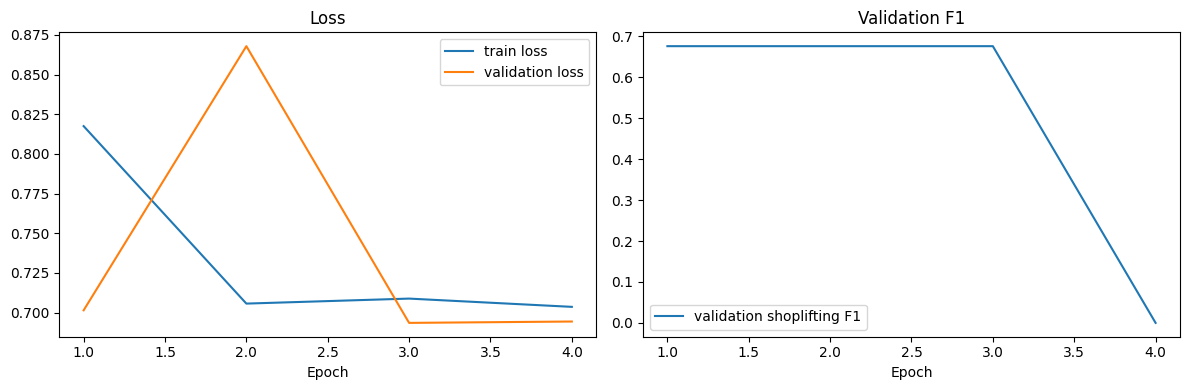

Saved split manifests to /kaggle/working


In [63]:
epochs_ran = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs_ran, history["train_loss"], label="train loss")
axes[0].plot(epochs_ran, history["val_loss"], label="validation loss")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(epochs_ran, history["val_f1"], label="validation shoplifting F1")
axes[1].set_title("Validation F1")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

train_df.to_csv(WORK_DIR / "train_split.csv", index=False)
val_df.to_csv(WORK_DIR / "validation_split.csv", index=False)
test_df.to_csv(WORK_DIR / "test_split.csv", index=False)
print("Saved split manifests to", WORK_DIR)

In [30]:
class ShopliftingVideoMAEClassifier(nn.Module):
    def __init__(self, model_name=MODEL_NAME, temporal_type="lstm", num_classes=2,
                 freeze_backbone=False, grad_checkpointing=False):
        super().__init__()
        self.videomae = VideoMAEModel.from_pretrained(model_name)
        cfg = self.videomae.config
        
        assert NUM_FRAMES == cfg.num_frames and IMAGE_SIZE == cfg.image_size, \
            f"model expects {cfg.num_frames} frames at {cfg.image_size}px"

        if grad_checkpointing:
            self.videomae.gradient_checkpointing_enable()
        for p in self.videomae.parameters():
            p.requires_grad = not freeze_backbone

        d = cfg.hidden_size                                     # 768
        self.t_steps = cfg.num_frames // cfg.tubelet_size       # 8 temporal tokens-groups
        self.temporal_type = temporal_type.lower()

        if self.temporal_type == "lstm":
            self.temporal_model = nn.LSTM(d, d // 2, num_layers=2, batch_first=True, dropout=0.3)
            feat_dim = d // 2
        elif self.temporal_type == "transformer":
            layer = nn.TransformerEncoderLayer(d, nhead=8, dim_feedforward=d * 2,
                                               dropout=0.3, batch_first=True)
            self.temporal_model = nn.TransformerEncoder(layer, num_layers=2)
            feat_dim = d
        else:
            raise ValueError("temporal_type must be 'lstm' or 'transformer'")

        self.classifier = nn.Sequential(
            nn.Linear(feat_dim, 128), nn.ReLU(inplace=True),
            nn.Dropout(0.4), nn.Linear(128, num_classes))

    def forward(self, x):                        
        # x: (B, T, C, H, W)
        if x.ndim == 5 and x.shape[1] == 3 and x.shape[2] != 3: 
            # Permute from (B, C, T, H, W) to (B, T, C, H, W)
            x = x.permute(0, 2, 1, 3, 4)
        tokens = self.videomae(pixel_values=x).last_hidden_state   # (B, t_steps * 196, D)
        B, _, D = tokens.shape
        seq = tokens.reshape(B, self.t_steps, -1, D).mean(dim=2)   # average the patches -> (B, t_steps, D)
        if self.temporal_type == "lstm":
            out, _ = self.temporal_model(seq)
            feat = out[:, -1]
        else:
            feat = self.temporal_model(seq).mean(dim=1)
        return self.classifier(feat)

model = ShopliftingVideoMAEClassifier(temporal_type=TEMPORAL_TYPE,
                                      grad_checkpointing=GRAD_CHECKPOINTING).to(device)
print(f"Trainable params: {sum(p.numel() for p in model.parameters() if p.requires_grad)/1e6:.1f}M")

# class weights for imbalance
y_train = train_df["label"].to_numpy()
counts = np.bincount(y_train, minlength=2)
class_weights = torch.tensor(len(y_train) / (2.0 * np.maximum(counts, 1)), dtype=torch.float32, device=device)
criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.AdamW([
    {"params": model.videomae.parameters(),        "lr": 2e-5},
    {"params": model.temporal_model.parameters(),  "lr": 1e-4},
    {"params": model.classifier.parameters(),      "lr": 1e-4},
], weight_decay=1e-2)

steps_per_epoch = math.ceil(len(train_loader) / ACCUM_STEPS)
total_steps = steps_per_epoch * EPOCHS
scheduler = get_cosine_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

Loading weights:   0%|          | 0/160 [00:00<?, ?it/s]

[transformers] VideoMAEModel LOAD REPORT from: MCG-NJU/videomae-base
Key                                                                  | Status     | 
---------------------------------------------------------------------+------------+-
videomae.encoder.layer.{0...11}.attention.attention.q_bias           | UNEXPECTED | 
decoder.head.bias                                                    | UNEXPECTED | 
decoder.decoder_layers.{0, 1, 2, 3}.attention.output.dense.weight    | UNEXPECTED | 
videomae.encoder.layer.{0...11}.attention.attention.v_bias           | UNEXPECTED | 
decoder.decoder_layers.{0, 1, 2, 3}.attention.attention.query.weight | UNEXPECTED | 
decoder.decoder_layers.{0, 1, 2, 3}.attention.attention.value.weight | UNEXPECTED | 
decoder.decoder_layers.{0, 1, 2, 3}.attention.attention.q_bias       | UNEXPECTED | 
decoder.decoder_layers.{0, 1, 2, 3}.intermediate.dense.bias          | UNEXPECTED | 
decoder.decoder_layers.{0, 1, 2, 3}.attention.attention.v_bias       | UNEXPECTED

Trainable params: 89.2M


In [31]:
def run_train_epoch(model, loader):
    model.train()
    optimizer.zero_grad(set_to_none=True)
    total_loss, correct, seen = 0.0, 0, 0
    for step, (x, y) in enumerate(tqdm(loader, desc="train", leave=False)):
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(x)
            loss = criterion(logits, y)
        scaler.scale(loss / ACCUM_STEPS).backward()

        if (step + 1) % ACCUM_STEPS == 0 or (step + 1) == len(loader):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer); scaler.update()
            optimizer.zero_grad(set_to_none=True)
            scheduler.step()

        total_loss += loss.item() * y.size(0)
        correct += (logits.argmax(1) == y).sum().item()
        seen += y.size(0)
    return total_loss / seen, correct / seen


@torch.no_grad()
def evaluate_model(model, loader):
    """Returns (avg_loss, y_true, y_pred, prob_of_shoplifting)."""
    model.eval()
    total_loss, ys, preds, probs = 0.0, [], [], []
    for x, y in tqdm(loader, desc="eval", leave=False):
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(x)
            loss = criterion(logits, y)
        total_loss += loss.item() * y.size(0)
        ys.append(y.cpu()); preds.append(logits.argmax(1).cpu())
        probs.append(torch.softmax(logits.float(), 1)[:, 1].cpu())
    y_true, y_pred, p = torch.cat(ys).numpy(), torch.cat(preds).numpy(), torch.cat(probs).numpy()
    return total_loss / len(y_true), y_true, y_pred, p


def save_atomic(obj, path):
    """Write to a temp file, then rename, so a crash mid-save never corrupts the checkpoint."""
    tmp = Path(str(path) + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)

META = dict(class_to_idx=CLASS_TO_IDX, num_frames=NUM_FRAMES, image_size=224,
            temporal_type=TEMPORAL_TYPE, mean=MEAN, std=STD)

In [32]:
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_f1": []}
start_epoch, best_val_f1, bad_epochs = 1, -1.0, 0

if RESUME and LAST_CKPT.exists():
    ck = torch.load(LAST_CKPT, map_location=device, weights_only=False)   # our own file, plain types
    model.load_state_dict(ck["model_state"])
    optimizer.load_state_dict(ck["optimizer_state"])
    scheduler.load_state_dict(ck["scheduler_state"])
    scaler.load_state_dict(ck["scaler_state"])
    history, best_val_f1, bad_epochs = ck["history"], ck["best_val_f1"], ck["bad_epochs"]
    start_epoch = ck["epoch"] + 1
    print(f"Resumed from epoch {ck['epoch']} (best val F1 so far {best_val_f1:.3f})")

for epoch in range(start_epoch, EPOCHS + 1):
    if bad_epochs >= PATIENCE:
        print("Early stopping already triggered."); break
    t0 = time.time()
    train_loss, train_acc = run_train_epoch(model, train_loader)
    val_loss, y_val, pred_val, _ = evaluate_model(model, val_loader)
    val_f1  = float(f1_score(y_val, pred_val, pos_label=1, zero_division=0))
    val_acc = float(accuracy_score(y_val, pred_val))

    history["train_loss"].append(float(train_loss)); history["train_acc"].append(float(train_acc))
    history["val_loss"].append(float(val_loss));     history["val_f1"].append(val_f1)
    print(f"Epoch {epoch:02d}/{EPOCHS} | train loss {train_loss:.4f} acc {train_acc:.3f} | "
          f"val loss {val_loss:.4f} acc {val_acc:.3f} F1 {val_f1:.3f} | {time.time()-t0:.0f}s")

    if val_f1 > best_val_f1:
        best_val_f1, bad_epochs = val_f1, 0
        save_atomic({"epoch": epoch, "model_state": model.state_dict(),
                     "best_val_f1": best_val_f1, **META}, BEST_CKPT)
        print(f"  saved best -> {BEST_CKPT}")
    else:
        bad_epochs += 1

    save_atomic({"epoch": epoch, "model_state": model.state_dict(),
                 "optimizer_state": optimizer.state_dict(), "scheduler_state": scheduler.state_dict(),
                 "scaler_state": scaler.state_dict(), "history": history,
                 "best_val_f1": best_val_f1, "bad_epochs": bad_epochs, **META}, LAST_CKPT)

    if bad_epochs >= PATIENCE:
        print("Early stopping: val F1 did not improve."); break

print(f"Done. Best validation F1: {best_val_f1:.3f}")

train:   0%|          | 0/112 [00:00<?, ?it/s]

eval:   0%|          | 0/24 [00:00<?, ?it/s]

Epoch 01/10 | train loss 0.6941 acc 0.508 | val loss 0.6926 acc 0.510 F1 0.676 | 326s
  saved best -> /kaggle/working/checkpoints_videomae/best.pt


train:   0%|          | 0/112 [00:00<?, ?it/s]

eval:   0%|          | 0/24 [00:00<?, ?it/s]

...

eval:   0%|          | 0/24 [00:00<?, ?it/s]

Epoch 06/10 | train loss 0.1603 acc 0.955 | val loss 0.2090 acc 0.938 F1 0.942 | 312s


train:   0%|          | 0/112 [00:00<?, ?it/s]

eval:   0%|          | 0/24 [00:00<?, ?it/s]

Epoch 07/10 | train loss 0.1652 acc 0.957 | val loss 0.2112 acc 0.938 F1 0.942 | 314s
Early stopping: val F1 did not improve.
Done. Best validation F1: 0.942


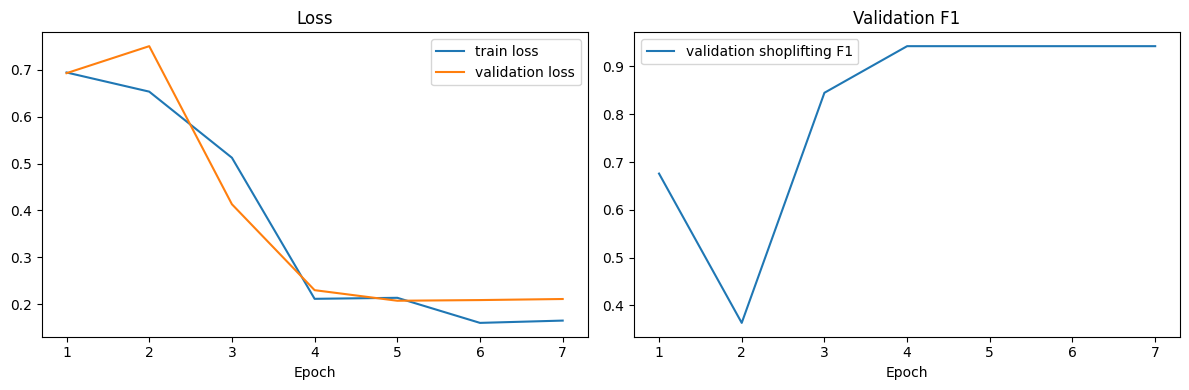

Saved split manifests to /kaggle/working


In [33]:
epochs_ran = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs_ran, history["train_loss"], label="train loss")
axes[0].plot(epochs_ran, history["val_loss"], label="validation loss")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(epochs_ran, history["val_f1"], label="validation shoplifting F1")
axes[1].set_title("Validation F1")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

train_df.to_csv(WORK_DIR / "train_split.csv", index=False)
val_df.to_csv(WORK_DIR / "validation_split.csv", index=False)
test_df.to_csv(WORK_DIR / "test_split.csv", index=False)
print("Saved split manifests to", WORK_DIR)

In [34]:
def test_model(ckpt_path=BEST_CKPT, loader=test_loader, save_name="test_predictions.csv"):
    if not Path(ckpt_path).exists():
        raise FileNotFoundError(f"{ckpt_path} not found - run the training cell first.")
    ck = torch.load(ckpt_path, map_location=device, weights_only=False)
    model.load_state_dict(ck["model_state"])
    print(f"Loaded {Path(ckpt_path).name} (epoch {ck['epoch']}, val F1 {ck.get('best_val_f1', float('nan')):.3f})")

    loss, y, pred, prob = evaluate_model(model, loader)
    metrics = {
        "loss": loss,
        "accuracy":  accuracy_score(y, pred),
        "precision": precision_score(y, pred, pos_label=1, zero_division=0),
        "recall":    recall_score(y, pred, pos_label=1, zero_division=0),
        "f1":        f1_score(y, pred, pos_label=1, zero_division=0),
    }
    print("\n=== Test results ===")
    for k, v in metrics.items():
        print(f"{k:10s}: {v:.4f}")
    print("\nConfusion matrix (rows = true, cols = predicted):\n", confusion_matrix(y, pred))
    print("\n", classification_report(y, pred, target_names=list(CLASS_TO_IDX), zero_division=0))

    out = loader.dataset.df[["path", "class"]].copy()
    out["pred"], out["prob_shoplifting"] = pred, prob
    out.to_csv(WORK_DIR / save_name, index=False)
    return metrics

test_metrics = test_model()

Loaded best.pt (epoch 4, val F1 0.942)


eval:   0%|          | 0/24 [00:00<?, ?it/s]


=== Test results ===
loss      : 0.0905
accuracy  : 0.9792
precision : 0.9608
recall    : 1.0000
f1        : 0.9800

Confusion matrix (rows = true, cols = predicted):
 [[45  2]
 [ 0 49]]

                   precision    recall  f1-score   support

non shop lifters       1.00      0.96      0.98        47
    shop lifters       0.96      1.00      0.98        49

        accuracy                           0.98        96
       macro avg       0.98      0.98      0.98        96
    weighted avg       0.98      0.98      0.98        96



In [43]:
import cv2
import numpy as np

def sample_frames(path, num_frames=16, image_size=224):
    """
    Sample frames uniformly across a video.

    Returns:
        NumPy array of shape (T, H, W, C), RGB, uint8.
    """
    cap = cv2.VideoCapture(str(path))

    if not cap.isOpened():
        raise ValueError(f"Cannot open video: {path}")

    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if frame_count <= 0:
        cap.release()
        raise ValueError(f"Video contains no readable frames: {path}")

    # Select T positions across the complete video.
    indices = np.linspace(
        0, frame_count - 1, num_frames
    ).astype(int)

    frames = []

    for idx in indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
        success, frame = cap.read()

        if not success:
            cap.release()
            raise ValueError(
                f"Failed to read frame {idx} from {path}"
            )

        # OpenCV uses BGR; the model expects RGB.
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        frame = cv2.resize(
            frame,
            (image_size, image_size),
            interpolation=cv2.INTER_LINEAR
        )

        frames.append(frame)

    cap.release()

    return np.stack(frames, axis=0)

In [46]:
@torch.no_grad()
def predict_video(path, ckpt_path=BEST_CKPT):
    ck = torch.load(ckpt_path, map_location=device, weights_only=False)
    model.load_state_dict(ck["model_state"]); model.eval()
    mean = torch.tensor(ck["mean"], dtype=torch.float32).view(1, 3, 1, 1)
    std  = torch.tensor(ck["std"],  dtype=torch.float32).view(1, 3, 1, 1)
    frames = sample_frames(path, ck["num_frames"], ck["image_size"])
    x = torch.from_numpy(frames).permute(0, 3, 1, 2).float() / 255.0
    x = ((x - mean) / std).unsqueeze(0).to(device)                     # (1, T, C, H, W)
    with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
        p = torch.softmax(model(x).float(), 1)[0].cpu().numpy()
    idx_to_class = {v: k for k, v in ck["class_to_idx"].items()}
    return idx_to_class[int(p.argmax())], float(p.max())

# example:
video_path = test_df["path"].iloc[30]

predicted_class, confidence = predict_video(video_path)

print("Video:", video_path)
print("Predicted class:", predicted_class)
print(f"Confidence:  ({confidence * 100:.2f}%)")

Video: /kaggle/working/dataset/Shop DataSet/shop lifters/videyyyyyyyyyss_26.mp4
Predicted class: shop lifters
Confidence:  (96.36%)
